In [1]:
from tqdm import tqdm
from req_functions_from_ApproxSP import *
from generate_profiles import *
from mallows import *
import json
from impartial import *
import pandas as pd
from euclidean import *


**Mallows**

In [4]:
data_mallows_gain = []

n=50
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1.0]

for phi1 in tqdm(phi_list):
    number_phi = []
    
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        
        for samples in range (100):
            cnt=0
            m_pref = [generate_ic_votes(n)[0]]*n
            w_pref = [generate_ic_votes(n)[0]]*n
            mpref= mallows_votes(m_pref, phi1)
            wpref= mallows_votes(w_pref, phi2)
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_mallows_gain.append([phi1, phi2, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)

100%|██████████| 6/6 [4:57:13<00:00, 2972.22s/it]


In [5]:
df2 = pd.DataFrame(data_mallows_gain, columns=["phi_m", "phi_w", "preferences", "sample", "manipulated preferences", "original matchings", "manipulated matchings", "benefit"])
df2.to_csv('mallows_gain_50.csv', index=False)

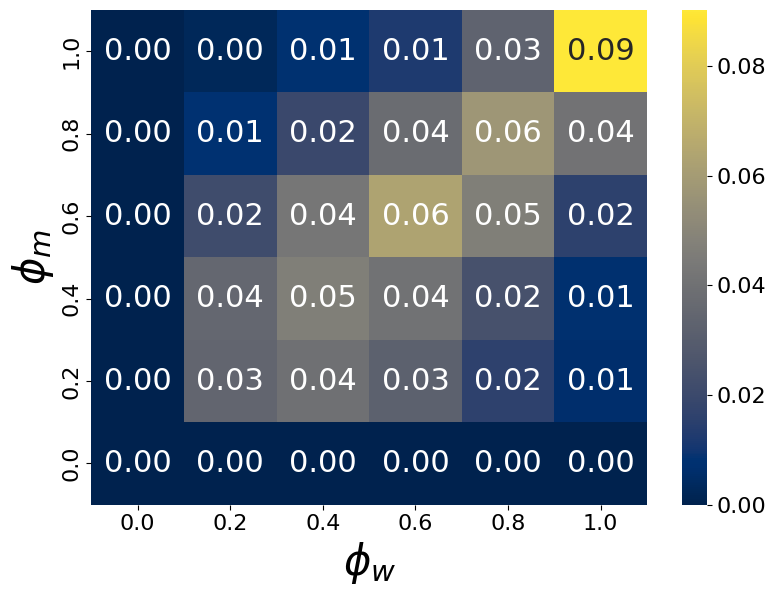

'\n# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---\nplt.figure(figsize=(8,6))\nheatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "freq_instance")\nsns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")\nplt.title("Frequency of Instance with ≥1 Manipulator")\nplt.xlabel(r"$\\phi_w$")\nplt.ylabel(r"$\\phi_m$")\nplt.gca().invert_yaxis()\nplt.tight_layout()\nplt.savefig("mallows_gain_self_freq_50.pdf", format=\'pdf\')\nplt.show()\n'

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_gain_50.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["avg_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.max(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("mallows_gain_50.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["phi_m", "phi_w"]).agg(
    avg_benefit=("avg_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()
'''
# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "avg_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Avg Self Benefit")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("mallows_gain_max_self_benefit_50.pdf", format='pdf')
plt.show()
'''
# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
grouped["avg_num_manipulators"] = grouped["avg_num_manipulators"] / 50

heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "avg_num_manipulators")
ax = sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="cividis", annot_kws={"size": 22})
#plt.title("Average Number of Manipulators")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize =30)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)
plt.savefig("mallows_self_avg_num_manipulators_50.pdf", format='pdf')
plt.show()

'''
# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("mallows_gain_self_freq_50.pdf", format='pdf')
plt.show()
'''

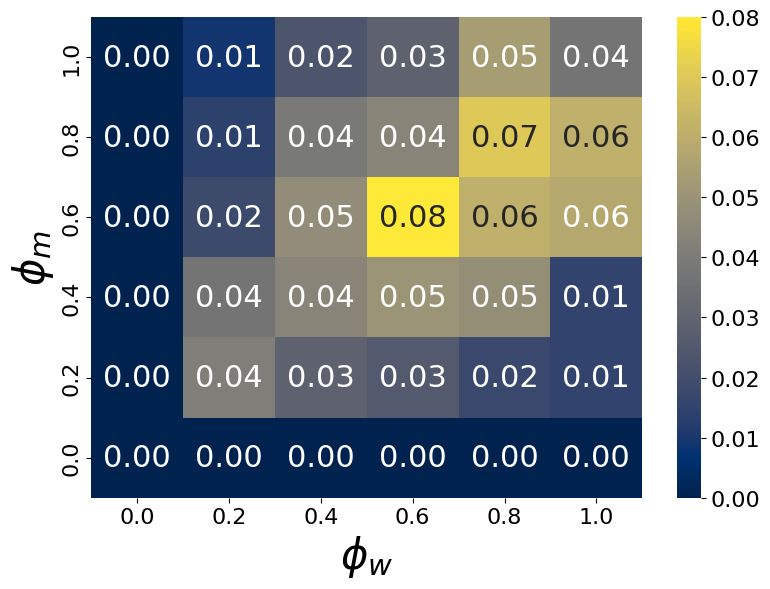

In [19]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["num_self_manipulators"].mean().reset_index()

heatmap_data["num_self_manipulators"] = heatmap_data["num_self_manipulators"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="num_self_manipulators")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="cividis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_self_10.pdf", format="pdf")
plt.show()


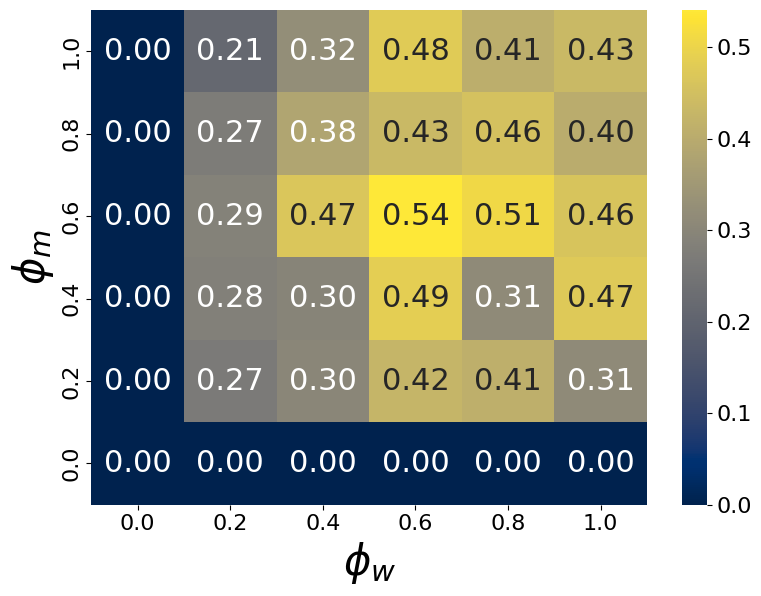

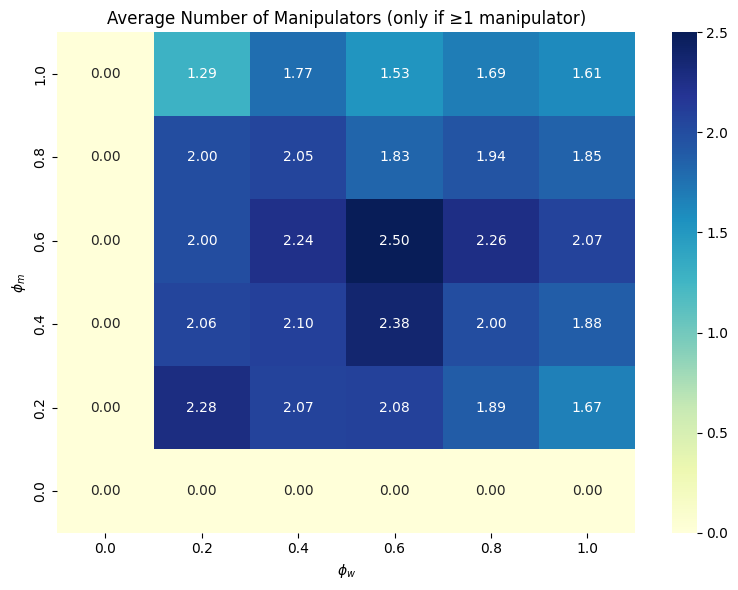

In [37]:
# --- Conditional averages: only over instances with at least one manipulator ---

# Filter rows where there is at least one manipulator
df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["phi_m", "phi_w"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["phi_m", "phi_w"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["phi_m", "phi_w"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["phi_m", "phi_w"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = avg_benefit_cond.pivot_table(
    index="phi_m", columns="phi_w", values="avg_self_benefit"
)

num_manip_cond_matrix = avg_num_manip_cond.pivot_table(
    index="phi_m", columns="phi_w", values="num_self_manipulators"
)

# --- Plotting ---

plt.figure(figsize=(8, 6))
ax = sns.heatmap(benefit_cond_matrix, annot=True, fmt=".2f", cmap="cividis", annot_kws={"size": 22})
#plt.title("Average Benefit (only if ≥1 manipulator)")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize = 30)
plt.tight_layout()
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.savefig("mallows_gain_avg_self_benefit_one.pdf", format='pdf')
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(num_manip_cond_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators (only if ≥1 manipulator)")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig("mallows_gain_num_self_manip_one.pdf", format='pdf')
plt.show()


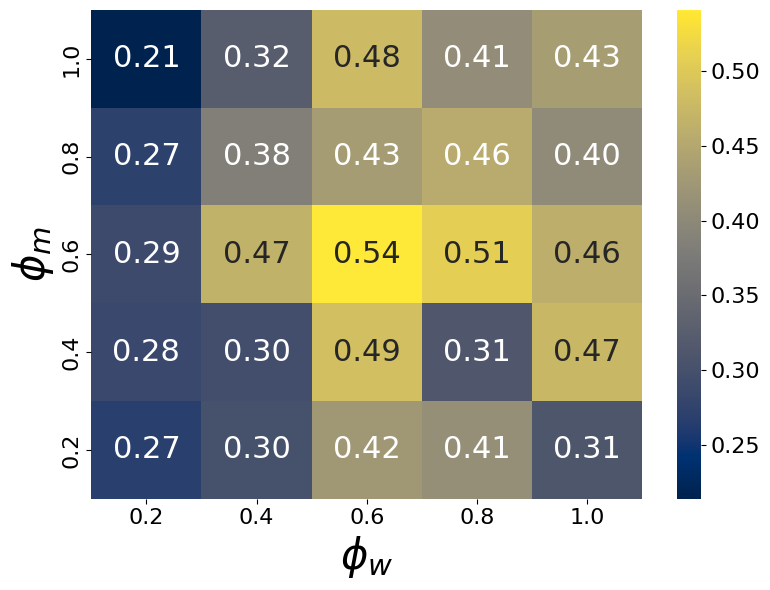

In [4]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_gain.csv")

df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["phi_m", "phi_w"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["phi_m", "phi_w"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["phi_m", "phi_w"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["phi_m", "phi_w"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = df_with_manip.pivot_table(
    index="phi_m", columns="phi_w", values="avg_self_benefit")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
#heatmap_data = benefit_cond_matrix.groupby(["phi_m", "phi_w"])["avg_self_benefit"].mean().reset_index()

pivot_table = benefit_cond_matrix
# Pivot for heatmap
#pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="avg_self_benefit")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="cividis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
#plt.savefig("mallows_gain_avg_self_benefit.pdf", format="pdf")
plt.show()


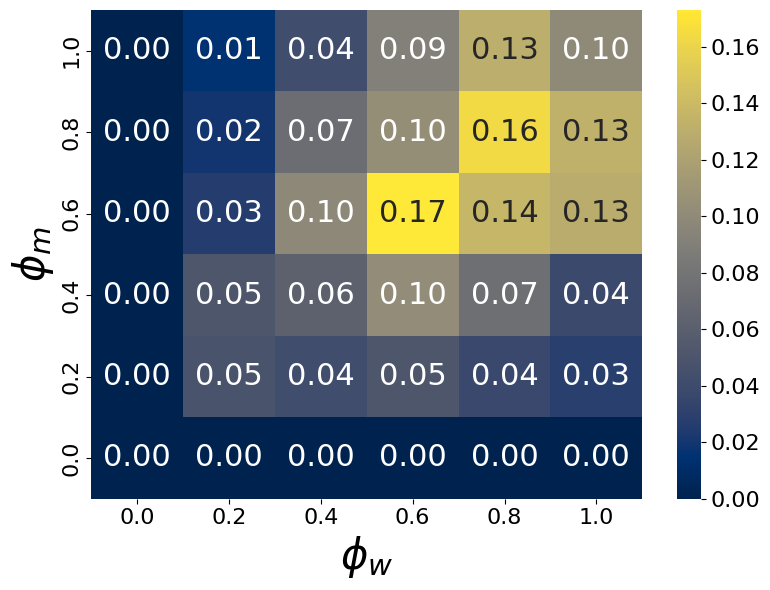

In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv("mallows_gain.csv")

# Unconditional average self benefit by (phi_m, phi_w)
avg_benefit = (
    df.groupby(["phi_m", "phi_w"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# Pivot for heatmap
pivot_table = avg_benefit.pivot(
    index="phi_m",
    columns="phi_w",
    values="avg_self_benefit"
)

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(
    pivot_table,
    annot=True,
    fmt=".2f",
    cmap="cividis",
    annot_kws={"size": 22}
)

plt.xlabel(r"$\phi_w$", fontsize=30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()
plt.savefig("mallows_gain_avg_self_benefit.pdf", format="pdf")
plt.show()


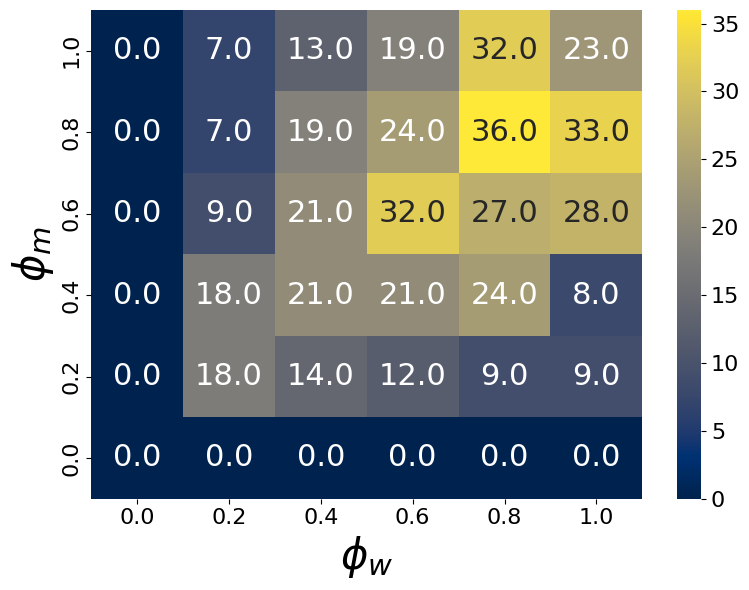

In [1]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_gain.csv")

# Safely convert string to list (if needed)
grouped = df.groupby(["phi_m", "phi_w"]).agg(
    max_benefit=("max_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = grouped.groupby(["phi_m", "phi_w"])["freq_instance"].sum().reset_index()


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="freq_instance")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".1f", cmap="cividis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_gain_self_freq.pdf", format="pdf")
plt.show()


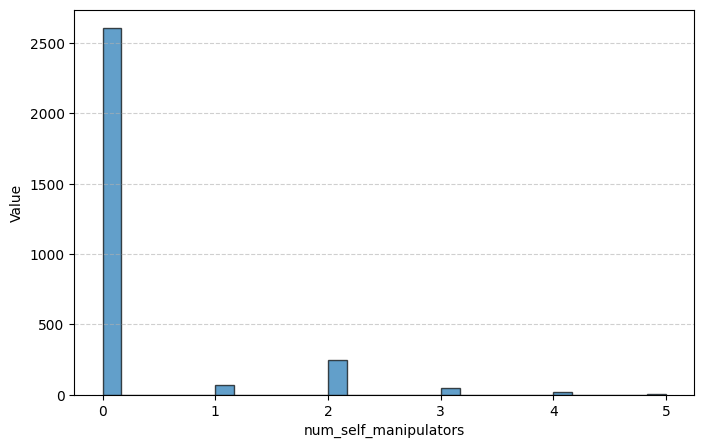

num_self_manipulators mean: 0.2727
num_self_manipulators median: 0.0000
num_self_manipulators max: 5.0000


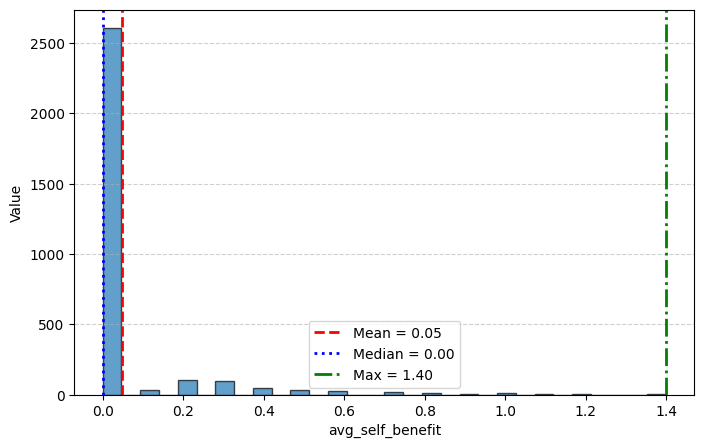

Mean of avg_self_benefit: 0.0490
Median of avg_self_benefit: 0.0000
Max of avg_self_benefit: 1.4000


In [7]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("CSV_Files/expectations_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())

#df = df[df["num_self_manipulators"] > 0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["num_self_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("num_self_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["num_self_manipulators"].mean()

median_val = df["num_self_manipulators"].median()

max_val = df["num_self_manipulators"].max()
 
print(f"num_self_manipulators mean: {mean_val:.4f}")

print(f"num_self_manipulators median: {median_val:.4f}")

print(f"num_self_manipulators max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("CSV_Files/expectations_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

#positive_df = df[df["avg_self_benefit"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(df["avg_self_benefit"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("avg_self_benefit")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = df["avg_self_benefit"].mean()

median_pos = df["avg_self_benefit"].median()

max_pos = df["avg_self_benefit"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of avg_self_benefit: {mean_pos:.4f}")

print(f"Median of avg_self_benefit: {median_pos:.4f}")

print(f"Max of avg_self_benefit: {max_pos:.4f}")

 

**Mallows MD**

In [150]:
data_mallows_MD_gain = []

n=10
phi_list=[1.0]

for phi1 in tqdm(phi_list):
    number_phi = []

    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]

        for samples in range (1000):
            cnt=0
            pref = generate_mallows_asymmetric_votes(n, phi1, phi2)
            mpref = pref[0]
            wpref = pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []

            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000

                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_mallows_MD_gain.append([phi1, phi2, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)

100%|██████████| 1/1 [00:00<00:00,  1.49it/s]


In [151]:
df3 = pd.DataFrame(data_mallows_MD_gain, columns=["phi_m", "phi_w", "preferences", "sample", "manipulated preference", "original matchings", "manipulated matchings", "benefit"])
df3.to_csv('mallows_MD_gain_test.csv', index=False)

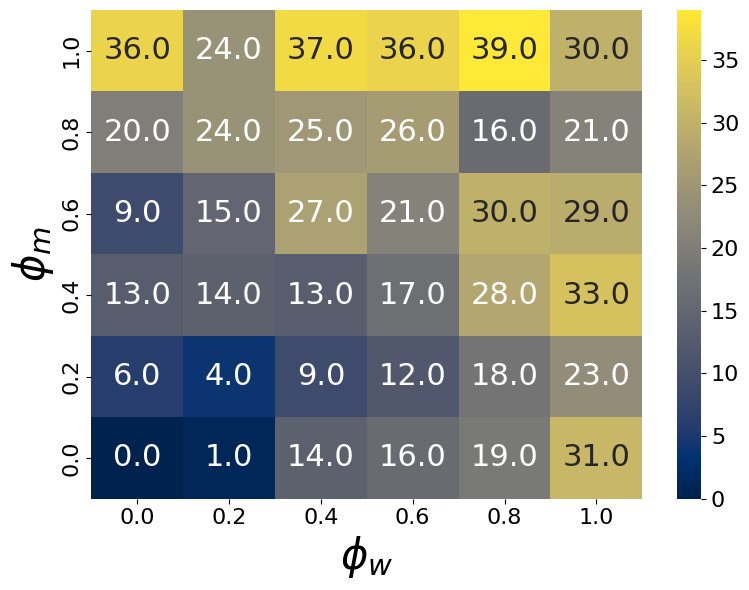

In [46]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["self_freq_instance"].mean().reset_index()

heatmap_data["self_freq_instance"] = heatmap_data["self_freq_instance"] * 100

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="self_freq_instance")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".1f", cmap="cividis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_euclidean_gain_self_freq.pdf", format="pdf")
plt.show()


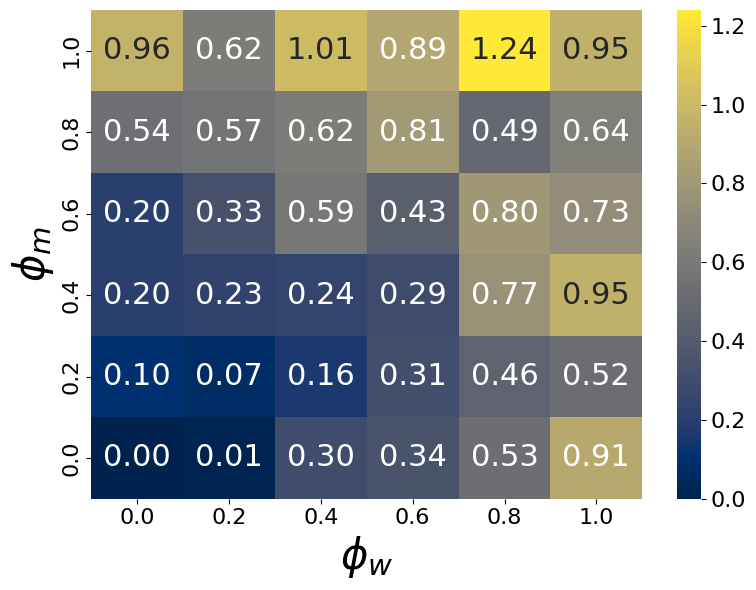

In [45]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["max_self_benefit"].mean().reset_index()


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="max_self_benefit")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="cividis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_euclidean_gain_max_self_benefit.pdf", format="pdf")
plt.show()


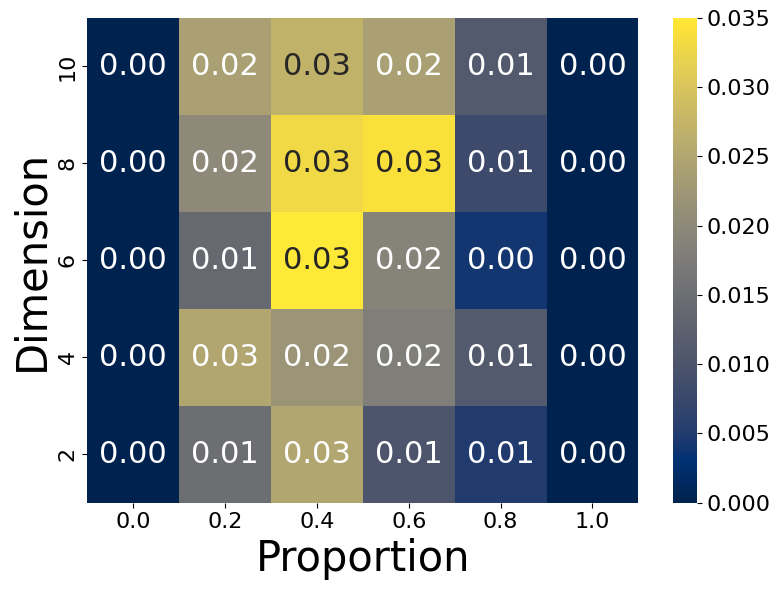

In [47]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("reverse_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "proportion"])["num_self_manipulators"].mean().reset_index()

heatmap_data["num_self_manipulators"] = heatmap_data["num_self_manipulators"] /10


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="proportion", values="num_self_manipulators")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="cividis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel("Proportion", fontsize = 30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("reverse_euclidean_gain_self_avg_num_manipulators.pdf", format="pdf")
plt.show()


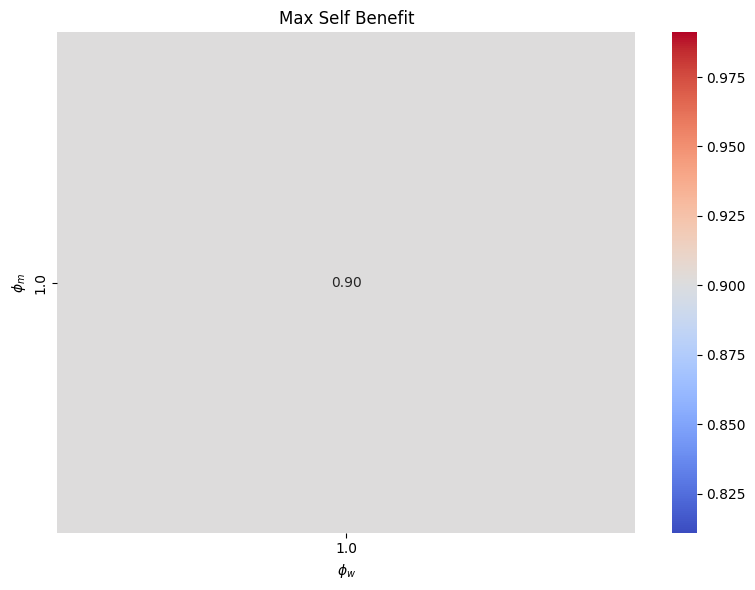

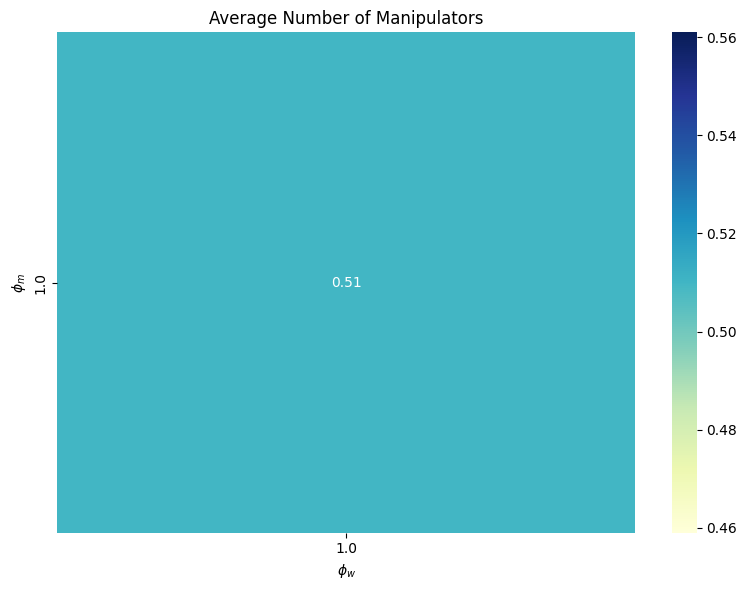

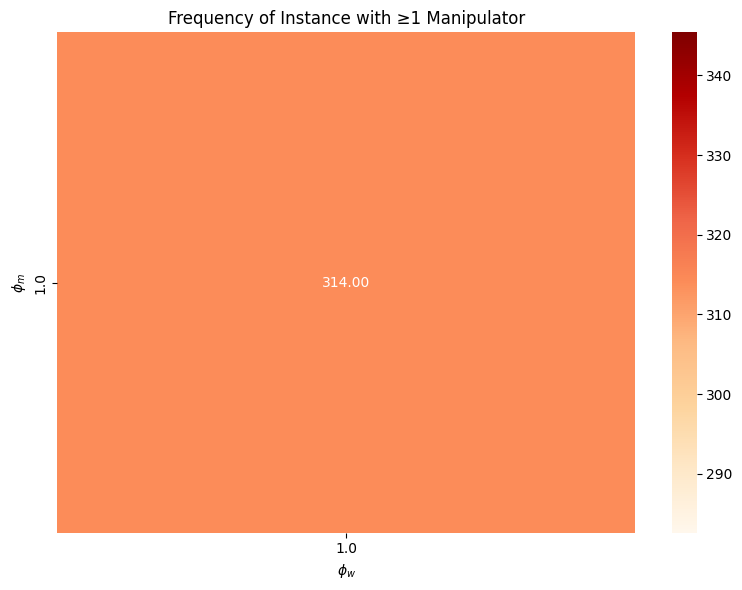

In [152]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_MD_gain_test.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["max_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.max(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("mallows_MD_gain_test.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["phi_m", "phi_w"]).agg(
    max_benefit=("max_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "max_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Max Self Benefit")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("mallows_MD_gain_max_self_benefit.pdf", format='pdf')
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
#plt.savefig("mallows_MD_gain_self_avg_num_manipulators.pdf", format='pdf')
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
#plt.savefig("mallows_MD_gain_self_freq.pdf", format='pdf')
plt.show()


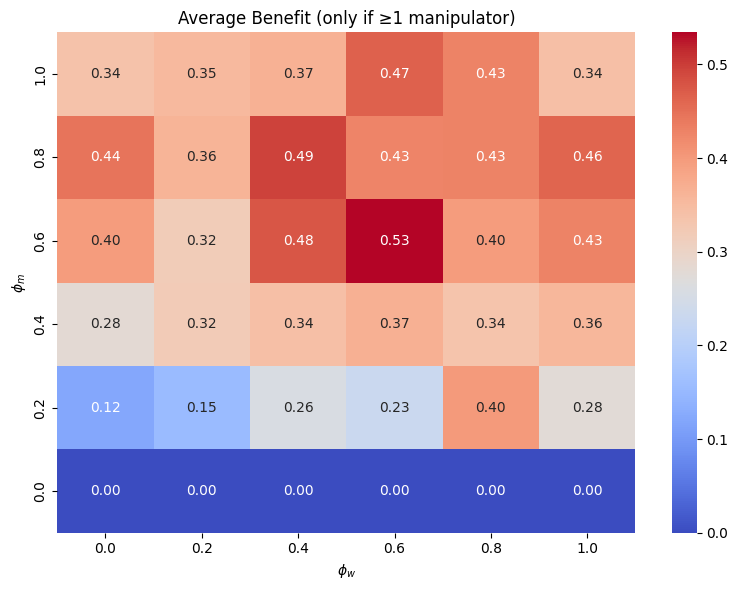

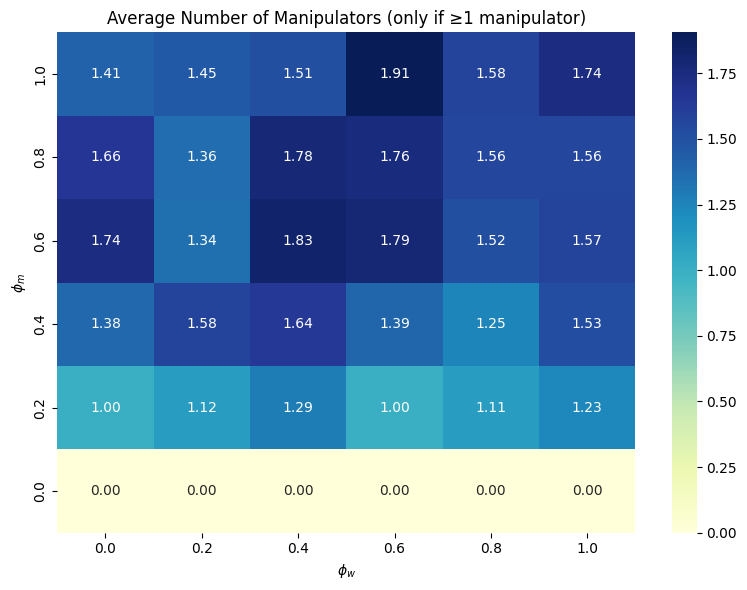

In [46]:
# --- Conditional averages: only over instances with at least one manipulator ---

# Filter rows where there is at least one manipulator
df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["phi_m", "phi_w"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["phi_m", "phi_w"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["phi_m", "phi_w"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["phi_m", "phi_w"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = avg_benefit_cond.pivot_table(
    index="phi_m", columns="phi_w", values="avg_self_benefit"
)

num_manip_cond_matrix = avg_num_manip_cond.pivot_table(
    index="phi_m", columns="phi_w", values="num_self_manipulators"
)

# --- Plotting ---

plt.figure(figsize=(8, 6))
sns.heatmap(benefit_cond_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit (only if ≥1 manipulator)")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig("mallows_MD_gain_avg_self_benefit_one.pdf", format='pdf')
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(num_manip_cond_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators (only if ≥1 manipulator)")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig("mallows_MD_gain_num_self_manip_one.pdf", format='pdf')
plt.show()


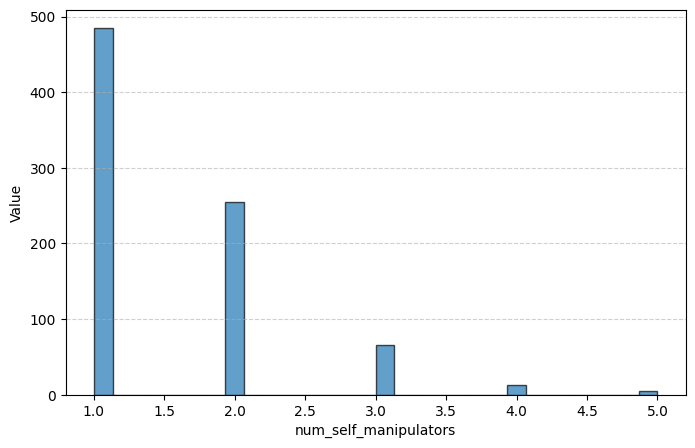

num_self_manipulators mean: 1.5395
num_self_manipulators median: 1.0000
num_self_manipulators max: 5.0000


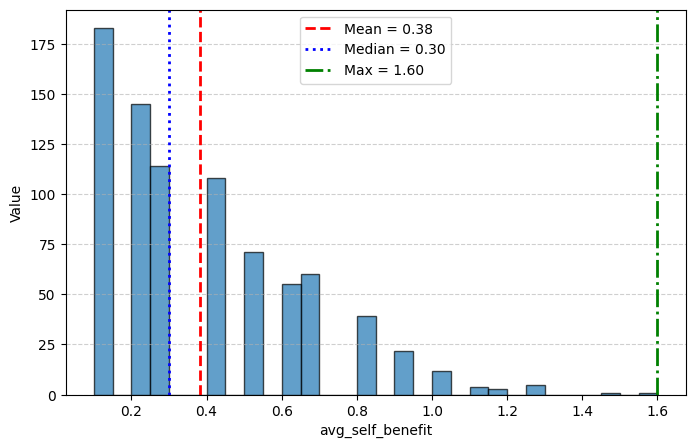

Mean of avg_self_benefit: 0.3837
Median of avg_self_benefit: 0.3000
Max of avg_self_benefit: 1.6000


In [3]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MD_gain.csv")
 
# Quick sanity check

#print(df.head())
 
# Plot distribution of avg_self_benefit

df = df[df["num_self_manipulators"] > 0]

plt.figure(figsize=(8, 5))

plt.hist(df["num_self_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("num_self_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["num_self_manipulators"].mean()

median_val = df["num_self_manipulators"].median()

max_val = df["num_self_manipulators"].max()
 
print(f"num_self_manipulators mean: {mean_val:.4f}")

print(f"num_self_manipulators median: {median_val:.4f}")

print(f"num_self_manipulators max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MD_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["avg_self_benefit"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["avg_self_benefit"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("avg_self_benefit")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["avg_self_benefit"].mean()

median_pos = positive_df["avg_self_benefit"].median()

max_pos = positive_df["avg_self_benefit"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of avg_self_benefit: {mean_pos:.4f}")

print(f"Median of avg_self_benefit: {median_pos:.4f}")

print(f"Max of avg_self_benefit: {max_pos:.4f}")

 

In [131]:
def generate_symmetric_votes(num_agents: int = None, **kwargs):
    num_rounds = num_agents - 1
    def next(agents):
        first = agents[0]
        last = agents[-1]
        middle = agents[1:-1]
        new_agents = [first, last]
        new_agents.extend(middle)
        return new_agents
    agents = [i for i in range(num_agents)]
    rounds = []
    for _ in range(num_rounds):
        pairs = []
        for i in range(num_agents // 2):
            agent_1 = agents[i]
            agent_2 = agents[num_agents - 1 - i]
            pairs.append([agent_1, agent_2])
        rounds.append(pairs)
        agents = next(agents)
    votes = np.zeros([num_agents, num_agents], dtype=int)
    for pos, partition in enumerate(rounds):
        for x, y in partition:
            votes[x][pos+1] = y
            votes[y][pos+1] = x
    for i in range(num_agents):
        votes[i][0] = i
    return [votes, votes]

def generate_mallows_MA_votes(num_agents: int = None,
                                      phi_m: float = None,
                                      phi_w: float = None,
                                      **kwargs):
    """ Mallows on top of Asymmetric instance """

    votes_left_array, votes_right_array = generate_symmetric_votes(num_agents=num_agents)


    votes_left_array = mallows_votes(votes_left_array, phi_m)
    votes_right_array = mallows_votes(votes_right_array, phi_w)

    votes_left = votes_left_array.tolist()
    votes_right = votes_right_array.tolist()

    j = 0
    for row in votes_left:
        for i in range(len(row)):
            votes_left[j][i] += 1
        j+=1
    j = 0
    for row in votes_right:
        for i in range(len(row)):
            votes_right[j][i] += 1
        j += 1


    return [votes_left, votes_right]

**Mallows MA**

In [132]:
generate_mallows_MA_votes(4, 0, 0)


[[[1, 4, 3, 2], [2, 3, 4, 1], [3, 2, 1, 4], [4, 1, 2, 3]],
 [[1, 4, 3, 2], [2, 3, 4, 1], [3, 2, 1, 4], [4, 1, 2, 3]]]

In [133]:
data_mallows_MA_gain = []

n=10
phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

for phi1 in tqdm(phi_list):
    number_phi = []

    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]

        for samples in range (100):
            cnt=0
            pref = generate_mallows_MA_votes(n, phi1, phi2)
            mpref = pref[0]
            wpref = pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []

            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000

                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_mallows_MA_gain.append([phi1, phi2, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)

100%|██████████| 6/6 [00:02<00:00,  2.59it/s]


In [134]:
df3 = pd.DataFrame(data_mallows_MA_gain, columns=["phi_m", "phi_w", "preferences", "sample", "manipulated preference", "original matchings", "manipulated matchings", "benefit"])
df3.to_csv('mallows_MA_gain.csv', index=False)

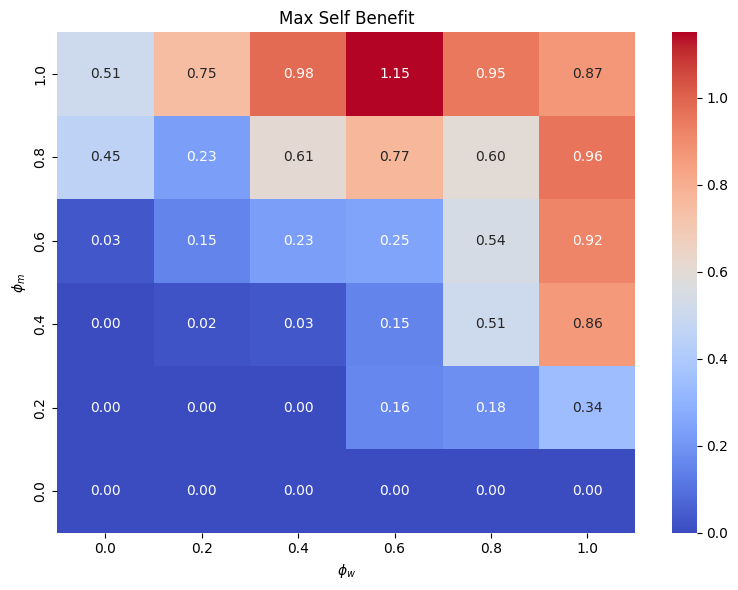

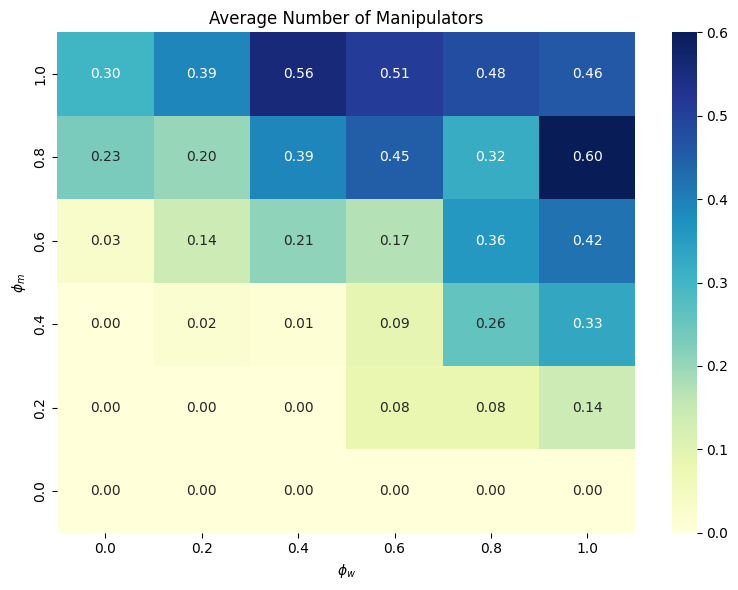

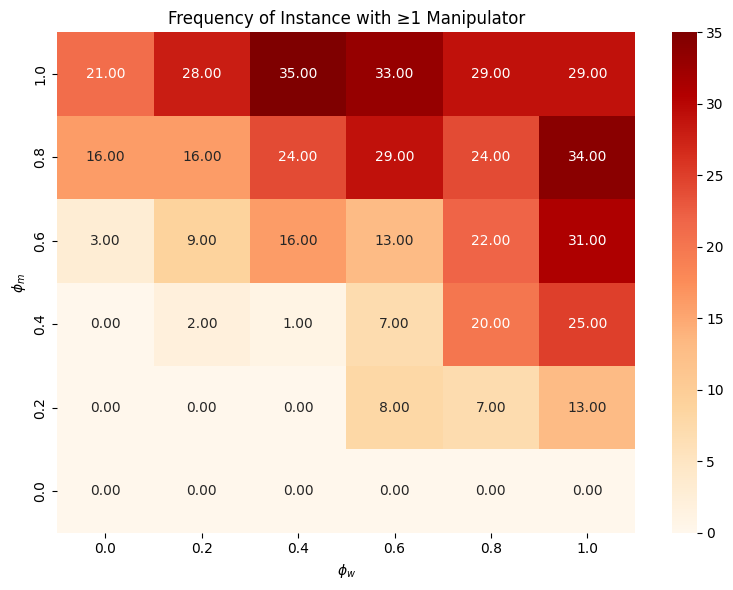

In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_MA_gain.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["max_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.max(lst) if lst else 0
)

df["avg_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.mean(lst) if lst else 0
)
# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("mallows_MA_gain.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["phi_m", "phi_w"]).agg(
    max_benefit=("max_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "max_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Max Self Benefit")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("mallows_MA_gain_max_self_benefit.pdf", format='pdf')
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("mallows_MA_gain_self_avg_num_manipulators.pdf", format='pdf')
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("mallows_MA_gain_self_freq.pdf", format='pdf')
plt.show()


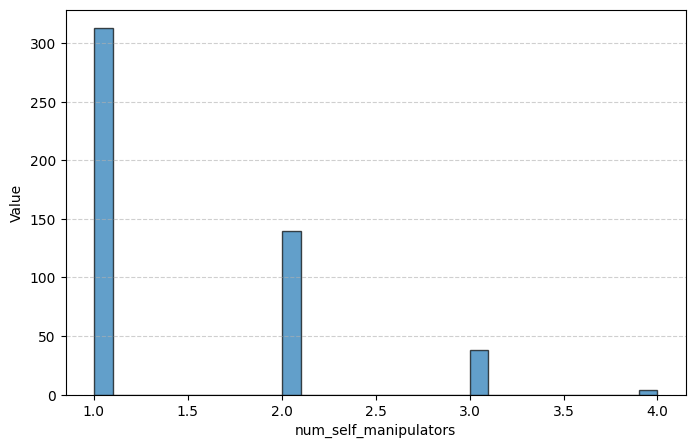

num_self_manipulators mean: 1.4606
num_self_manipulators median: 1.0000
num_self_manipulators max: 4.0000


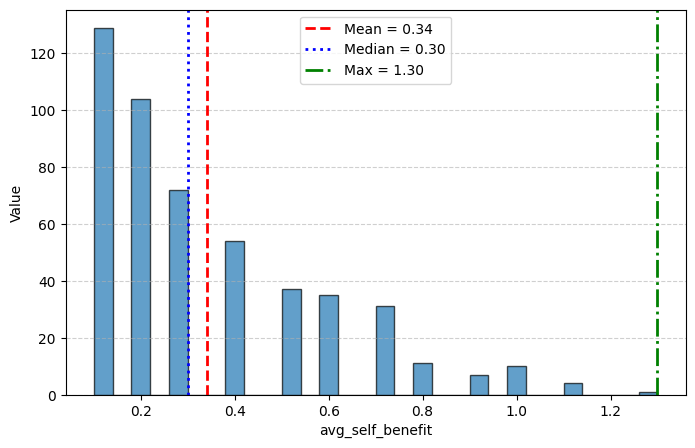

Mean of avg_self_benefit: 0.3412
Median of avg_self_benefit: 0.3000
Max of avg_self_benefit: 1.3000


In [5]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MA_gain.csv")
 
# Quick sanity check

#print(df.head())

df = df[df["num_self_manipulators"] > 0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["num_self_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("num_self_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["num_self_manipulators"].mean()

median_val = df["num_self_manipulators"].median()

max_val = df["num_self_manipulators"].max()
 
print(f"num_self_manipulators mean: {mean_val:.4f}")

print(f"num_self_manipulators median: {median_val:.4f}")

print(f"num_self_manipulators max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MA_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["avg_self_benefit"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["avg_self_benefit"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("avg_self_benefit")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["avg_self_benefit"].mean()

median_pos = positive_df["avg_self_benefit"].median()

max_pos = positive_df["avg_self_benefit"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of avg_self_benefit: {mean_pos:.4f}")

print(f"Median of avg_self_benefit: {median_pos:.4f}")

print(f"Max of avg_self_benefit: {max_pos:.4f}")

 

**Mallows Euclidean**

In [153]:
data_mallows_euclidean_gain = []

n=10
phi_list=[1.0]

for phi1 in tqdm(phi_list):
    number_phi = []

    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]

        for samples in range (1000):
            cnt=0
            pref = generate_mallows_euclidean_votes(n, phi1, phi2)
            mpref = pref[0]
            wpref = pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []

            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000

                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]

                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_mallows_euclidean_gain.append([phi1, phi2, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])


            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)

100%|██████████| 1/1 [00:01<00:00,  1.11s/it]


In [154]:
df3 = pd.DataFrame(data_mallows_euclidean_gain, columns=["phi_m", "phi_w", "preferences", "sample", "manipulated preference", "original matchings", "manipulated matchings", "benefit"])
df3.to_csv('mallows_euclidean_gain_test.csv', index=False)

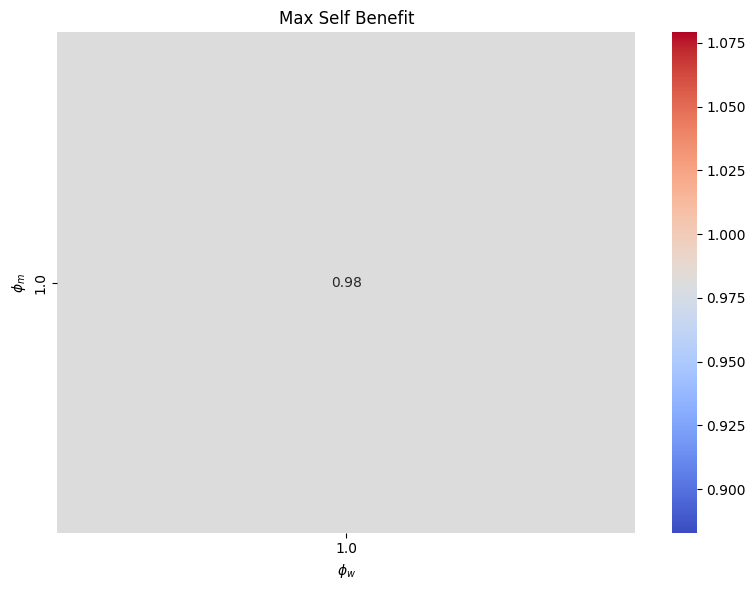

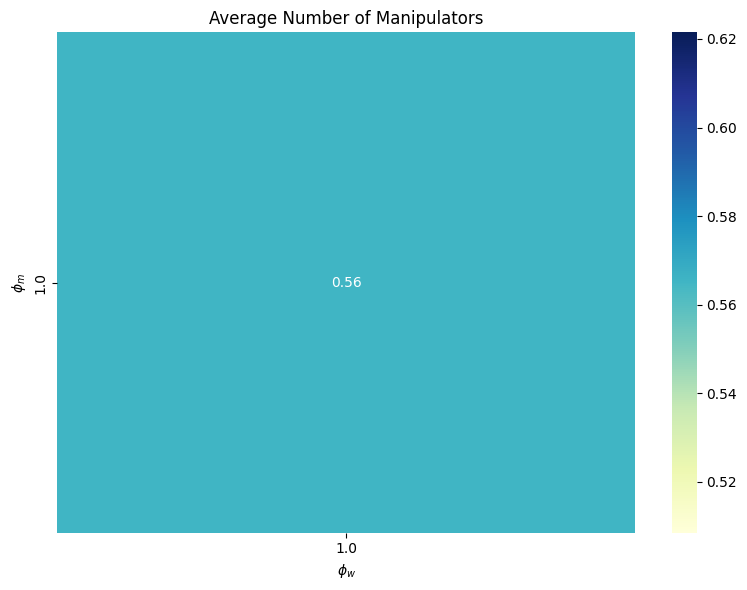

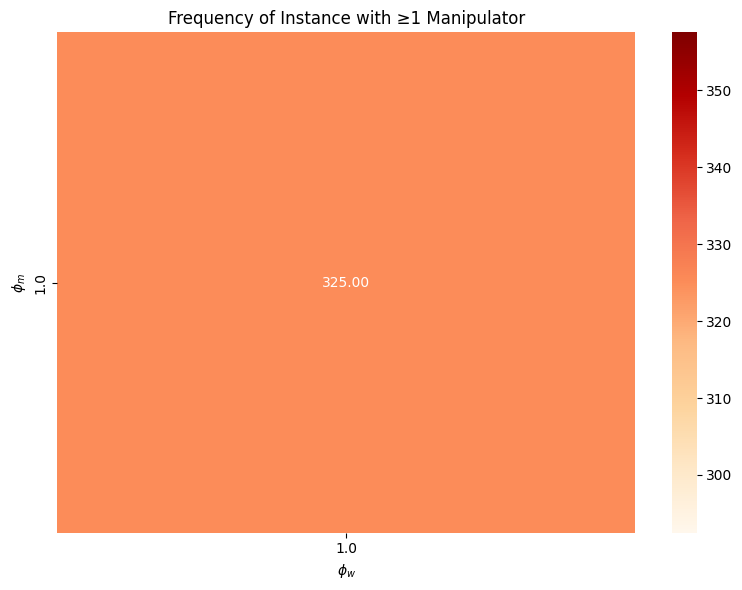

In [155]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_euclidean_gain_test.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["max_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.max(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("mallows_euclidean_gain_test.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["phi_m", "phi_w"]).agg(
    max_benefit=("max_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "max_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Max Self Benefit")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("mallows_euclidean_gain_max_self_benefit.pdf", format='pdf')
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("mallows_euclidean_gain_self_avg_num_manipulators.pdf", format='pdf')
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "phi_m", columns = "phi_w", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("mallows_euclidean_gain_self_freq.pdf", format='pdf')
plt.show()


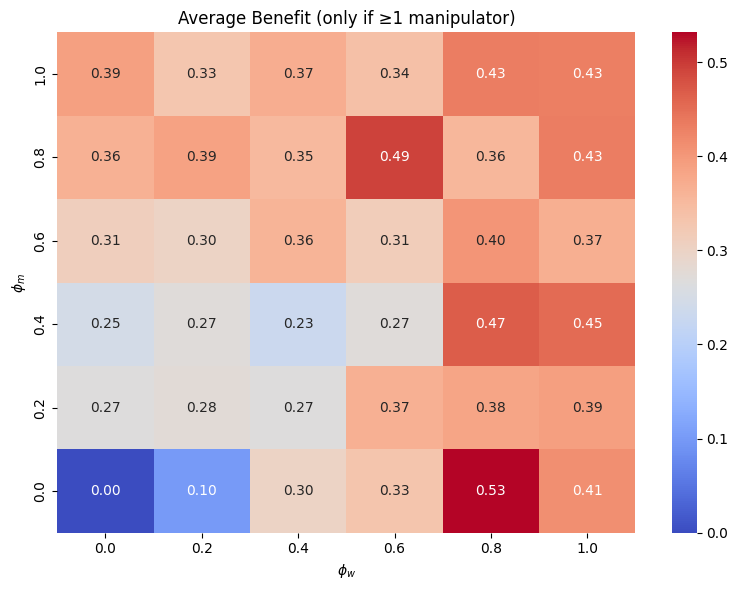

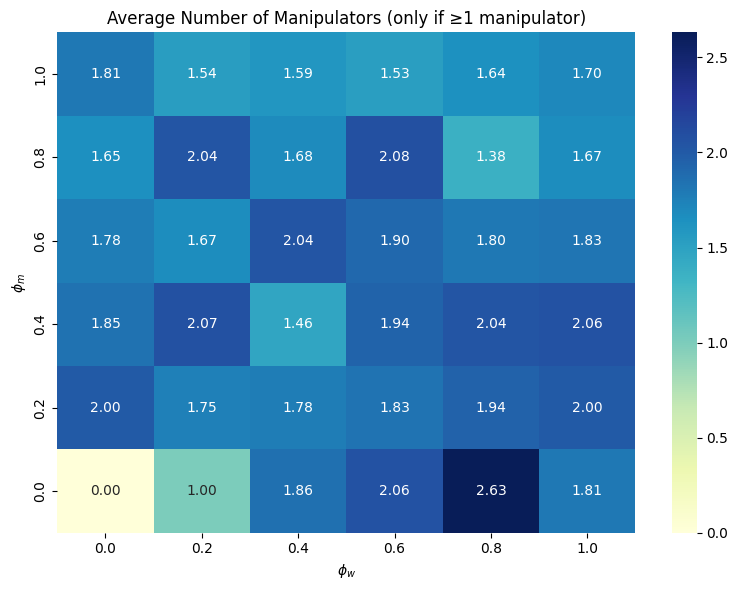

In [48]:
# --- Conditional averages: only over instances with at least one manipulator ---

# Filter rows where there is at least one manipulator
df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["phi_m", "phi_w"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["phi_m", "phi_w"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["phi_m", "phi_w"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["phi_m", "phi_w"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["phi_m", "phi_w"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = avg_benefit_cond.pivot_table(
    index="phi_m", columns="phi_w", values="avg_self_benefit"
)

num_manip_cond_matrix = avg_num_manip_cond.pivot_table(
    index="phi_m", columns="phi_w", values="num_self_manipulators"
)

# --- Plotting ---

plt.figure(figsize=(8, 6))
sns.heatmap(benefit_cond_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit (only if ≥1 manipulator)")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig("mallows_euclidean_gain_avg_self_benefit_one.pdf", format='pdf')
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(num_manip_cond_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators (only if ≥1 manipulator)")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig("mallows_euclidean_gain_num_self_manip_one.pdf", format='pdf')
plt.show()


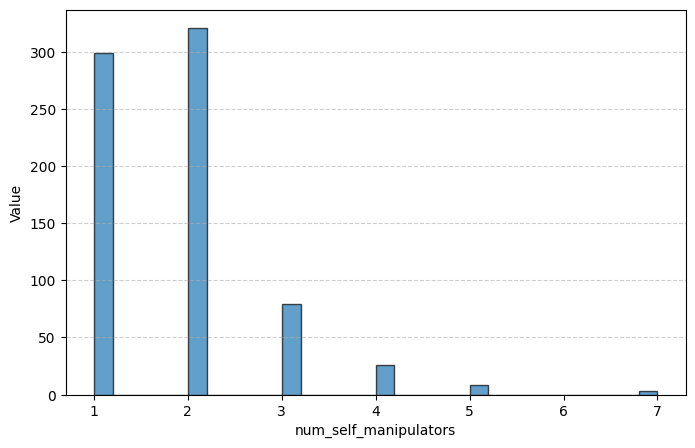

num_self_manipulators mean: 1.8247
num_self_manipulators median: 2.0000
num_self_manipulators max: 7.0000


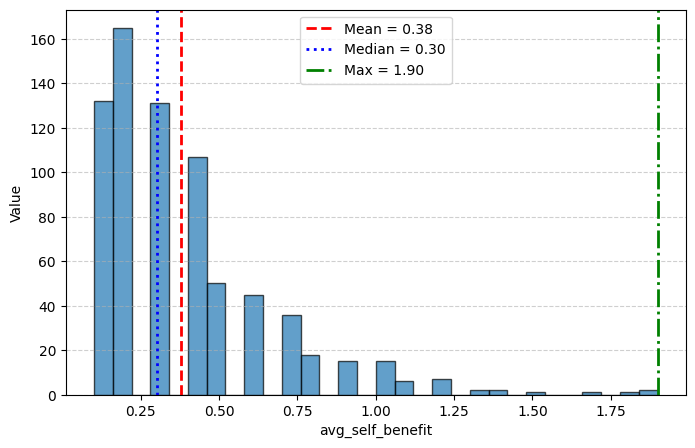

Mean of avg_self_benefit: 0.3772
Median of avg_self_benefit: 0.3000
Max of avg_self_benefit: 1.9000


In [6]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())

df= df[df["num_self_manipulators"] > 0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["num_self_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("num_self_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["num_self_manipulators"].mean()

median_val = df["num_self_manipulators"].median()

max_val = df["num_self_manipulators"].max()
 
print(f"num_self_manipulators mean: {mean_val:.4f}")

print(f"num_self_manipulators median: {median_val:.4f}")

print(f"num_self_manipulators max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["avg_self_benefit"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["avg_self_benefit"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("avg_self_benefit")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["avg_self_benefit"].mean()

median_pos = positive_df["avg_self_benefit"].median()

max_pos = positive_df["avg_self_benefit"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of avg_self_benefit: {mean_pos:.4f}")

print(f"Median of avg_self_benefit: {median_pos:.4f}")

print(f"Max of avg_self_benefit: {max_pos:.4f}")

 

**Reverse Euclidean**

In [11]:
data_reverse_euclidean_gain = []

n=10
p_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10]

for d in tqdm(d_list):
    number_phi = []
    for p in tqdm(p_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            pref=generate_reverse_euclidean_votes(n, d, 'uniform', 0.5, p)
            mpref=pref[0]
            wpref=pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                #print(rk1, rk2)
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_reverse_euclidean_gain.append([d, p, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                #save phim, phiw, sample, manipulator, manipulated_preference (that would be result[1]), matching, matching2, benefit 
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)




100%|██████████| 5/5 [00:02<00:00,  1.76it/s]


In [12]:
df5 = pd.DataFrame(data_reverse_euclidean_gain, columns=["dimension", "proportion", "preferences", "sample", "manipulated preference", "original matching", "manipulated matching", "benefit"])
df5.to_csv('reverse_euclidean_gain.csv', index=False)

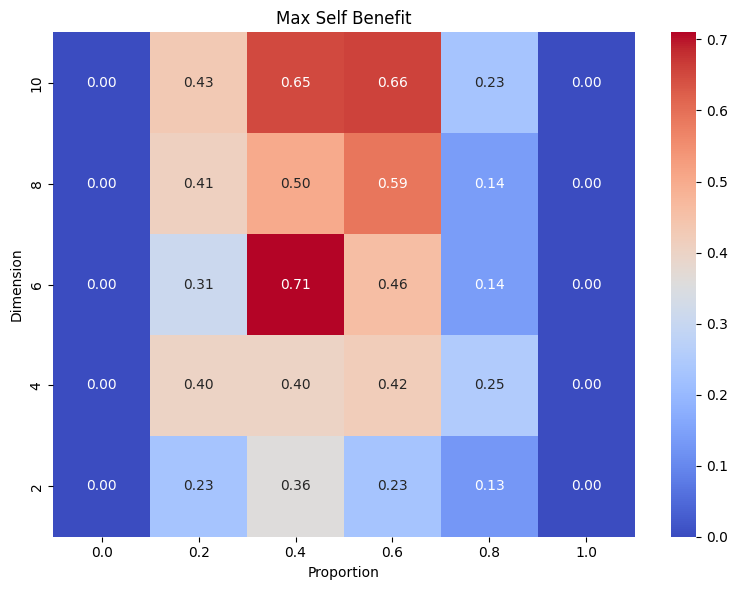

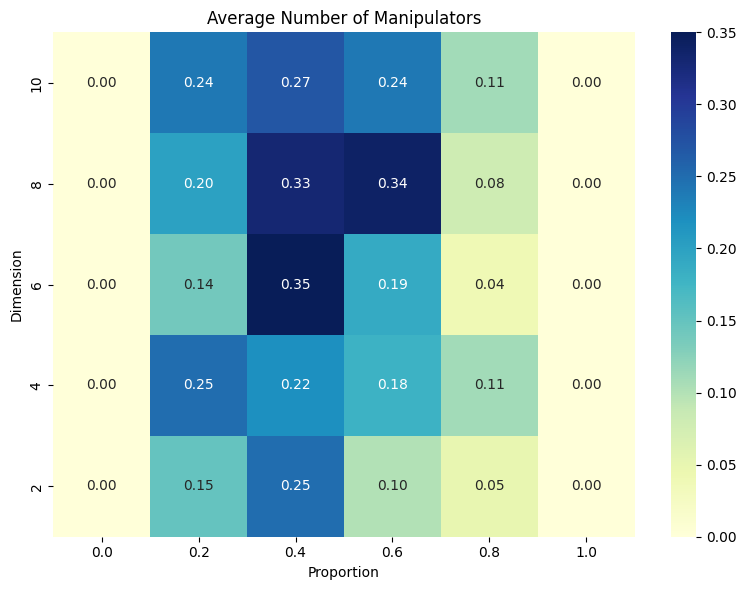

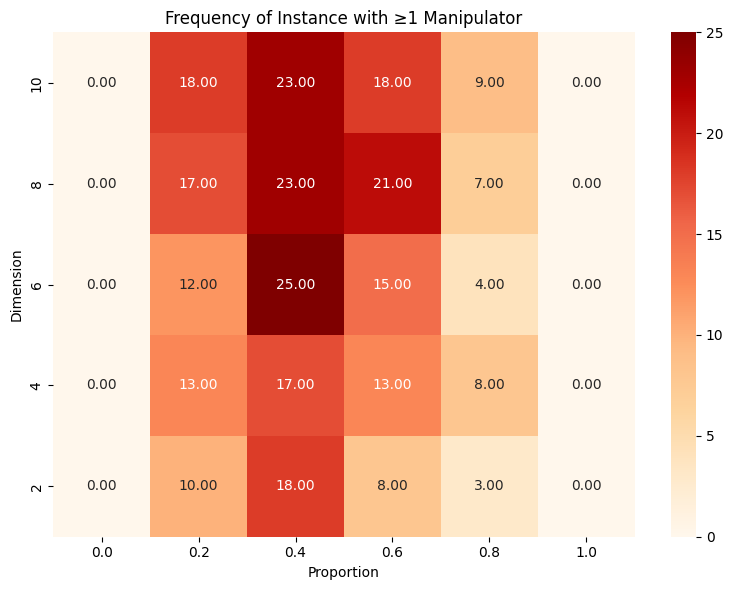

In [73]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("reverse_euclidean_gain.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["max_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.max(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("reverse_euclidean_gain.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["dimension", "proportion"]).agg(
    max_benefit=("max_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "proportion", values = "max_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Max Self Benefit")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("reverse_euclidean_gain_max_self_benefit.pdf", format='pdf')
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "proportion", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("reverse_euclidean_gain_self_avg_num_manipulators.pdf", format='pdf')
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "proportion", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("reverse_euclidean_gain_self_freq.pdf", format='pdf')
plt.show()


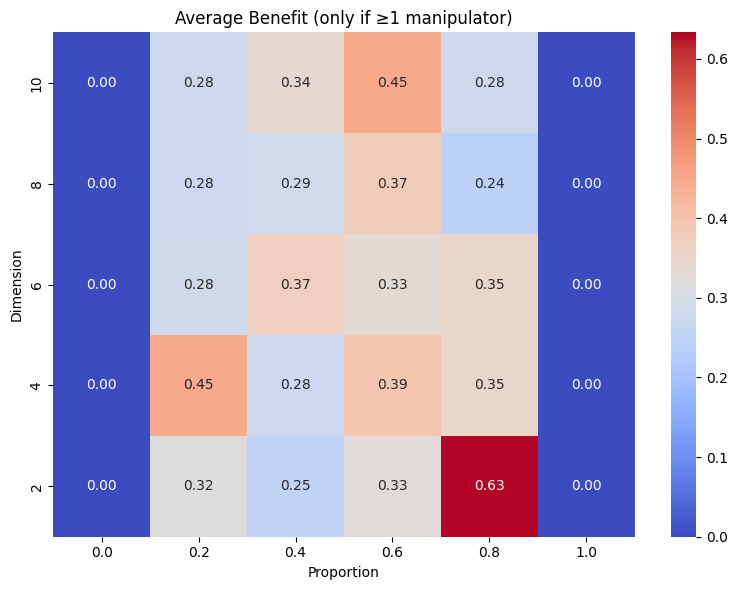

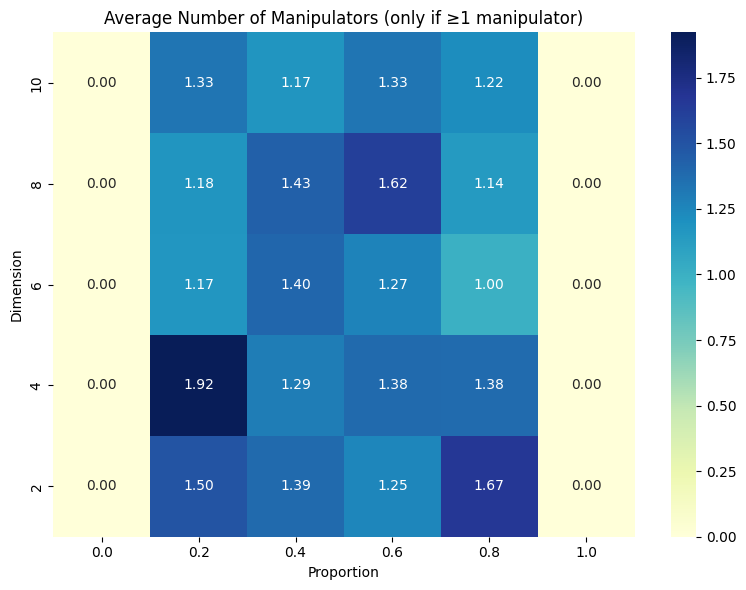

In [50]:
# --- Conditional averages: only over instances with at least one manipulator ---

# Filter rows where there is at least one manipulator
df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["dimension", "proportion"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["dimension", "proportion"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["dimension", "proportion"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["dimension", "proportion"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["dimension", "proportion"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["dimension", "proportion"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = avg_benefit_cond.pivot_table(
    index="dimension", columns="proportion", values="avg_self_benefit"
)

num_manip_cond_matrix = avg_num_manip_cond.pivot_table(
    index="dimension", columns="proportion", values="num_self_manipulators"
)

# --- Plotting ---

plt.figure(figsize=(8, 6))
sns.heatmap(benefit_cond_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit (only if ≥1 manipulator)")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig("reverse_euclidean_gain_avg_self_benefit_one.pdf", format='pdf')
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(num_manip_cond_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators (only if ≥1 manipulator)")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig("reverse_euclidean_gain_num_self_manip_one.pdf", format='pdf')
plt.show()


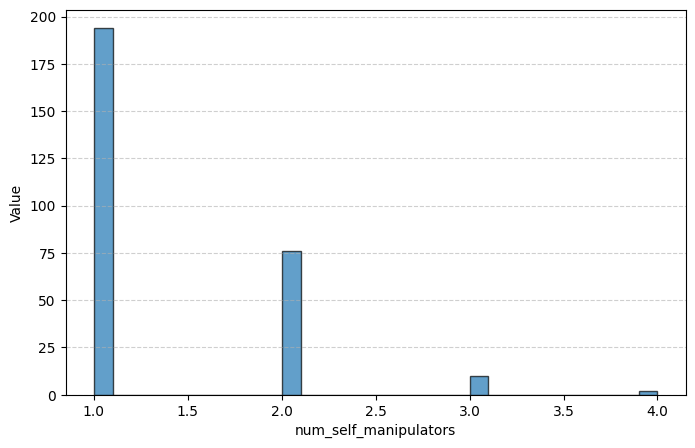

num_self_manipulators mean: 1.3617
num_self_manipulators median: 1.0000
num_self_manipulators max: 4.0000


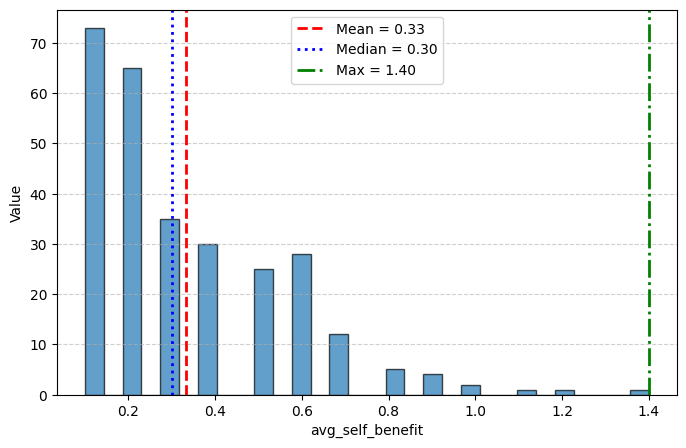

Mean of avg_self_benefit: 0.3326
Median of avg_self_benefit: 0.3000
Max of avg_self_benefit: 1.4000


In [7]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("reverse_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())

df= df[df["num_self_manipulators"] > 0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["num_self_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("num_self_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["num_self_manipulators"].mean()

median_val = df["num_self_manipulators"].median()

max_val = df["num_self_manipulators"].max()
 
print(f"num_self_manipulators mean: {mean_val:.4f}")

print(f"num_self_manipulators median: {median_val:.4f}")

print(f"num_self_manipulators max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("reverse_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["avg_self_benefit"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["avg_self_benefit"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("avg_self_benefit")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["avg_self_benefit"].mean()

median_pos = positive_df["avg_self_benefit"].median()

max_pos = positive_df["avg_self_benefit"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of avg_self_benefit: {mean_pos:.4f}")

print(f"Median of avg_self_benefit: {median_pos:.4f}")

print(f"Max of avg_self_benefit: {max_pos:.4f}")

 

**Expectations Euclidean**

In [13]:
import numpy as np

def convert_to_builtin(obj):
    if isinstance(obj, dict):
        return {convert_to_builtin(k): convert_to_builtin(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [convert_to_builtin(elem) for elem in obj]
    elif isinstance(obj, np.integer):
        return int(obj)
    elif isinstance(obj, np.floating):
        return float(obj)
    else:
        return obj
    
import numpy as np

def generate_expectation_votes(num_agents: int = None,
                               dim: int = None,
                               space='uniform',
                               std: float = None,
                               phi=0.5,
                               **kwargs):
    name = f'{dim}d_{space}'

    left_agents_reality = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    left_agents_wishes = np.zeros([num_agents, dim])

    right_agents_reality = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    right_agents_wishes = np.zeros([num_agents, dim])

    for v in range(num_agents):
        # while agents_wishes[v][0] <= 0 or agents_wishes[v][0] >= 1:
        left_agents_wishes[v][0] = np.random.normal(left_agents_reality[v][0], std)
        # while agents_wishes[v][1] <= 0 or agents_wishes[v][1] >= 1:
        left_agents_wishes[v][1] = np.random.normal(left_agents_reality[v][1], std)

        # while agents_wishes[v][0] <= 0 or agents_wishes[v][0] >= 1:
        right_agents_wishes[v][0] = np.random.normal(right_agents_reality[v][0], std)
        # while agents_wishes[v][1] <= 0 or agents_wishes[v][1] >= 1:
        right_agents_wishes[v][1] = np.random.normal(right_agents_reality[v][1], std)

    left_votes = np.zeros([num_agents, num_agents], dtype=int)
    right_votes = np.zeros([num_agents, num_agents], dtype=int)
    distances = np.zeros([num_agents, num_agents], dtype=float)

    for v in range(num_agents):
        for c in range(num_agents):
            left_votes[v][c] = c
            distances[v][c] = np.linalg.norm(right_agents_reality[c] - left_agents_wishes[v])
        left_votes[v] = [x for _, x in sorted(zip(distances[v], left_votes[v]))]

    for v in range(num_agents):
        for c in range(num_agents):
            right_votes[v][c] = c
            distances[v][c] = np.linalg.norm(left_agents_reality[c] - right_agents_wishes[v])
        right_votes[v] = [x for _, x in sorted(zip(distances[v], right_votes[v]))]

    left_votes_lst = [list(row) for row in left_votes]
    right_votes_lst = [list(row) for row in right_votes]


    for i in range(len(left_votes_lst)):
        for j in range(len(left_votes_lst[i])):
            left_votes_lst[i][j] = left_votes_lst[i][j] + 1
    for i in range(len(right_votes_lst)):
        for j in range(len(right_votes_lst[i])):
            right_votes_lst[i][j] = right_votes_lst[i][j] + 1

    return [left_votes_lst, right_votes_lst]

In [38]:
data_expectations_euclidean_gain = []

n=10
std_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10]

for d in tqdm(d_list):
    number_phi = []
    for std in tqdm(std_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            pref=generate_expectation_votes(n, d, 'uniform', std, 0.5)
            mpref=pref[0]
            wpref=pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                #print(rk1, rk2)
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_expectations_euclidean_gain.append([d, std, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                #save phim, phiw, sample, manipulator, manipulated_preference (that would be result[1]), matching, matching2, benefit 
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)




100%|██████████| 5/5 [00:05<00:00,  1.07s/it]


In [39]:
df6 = pd.DataFrame(data_expectations_euclidean_gain, columns=["dimension", "std", "preferences", "sample", "manipulated preference", "original matching", "manipulated matching", "benefit"])
df6.to_csv('expectations_euclidean_gain.csv', index=False)

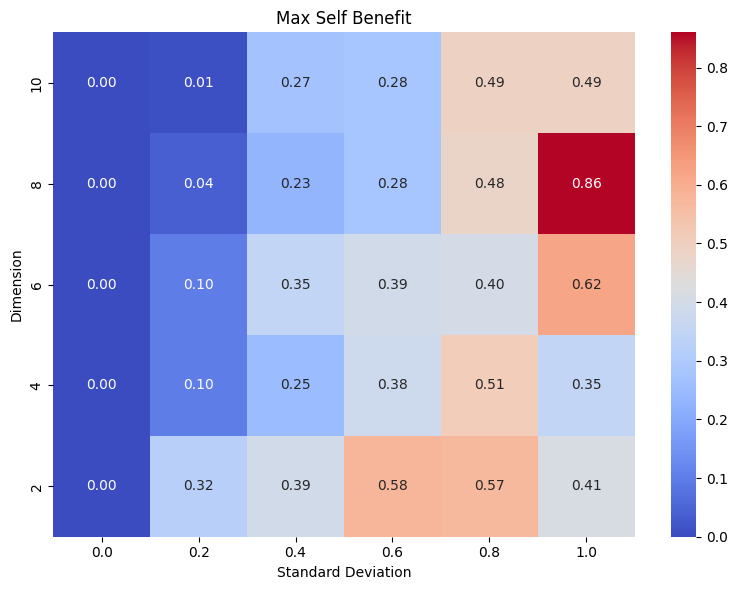

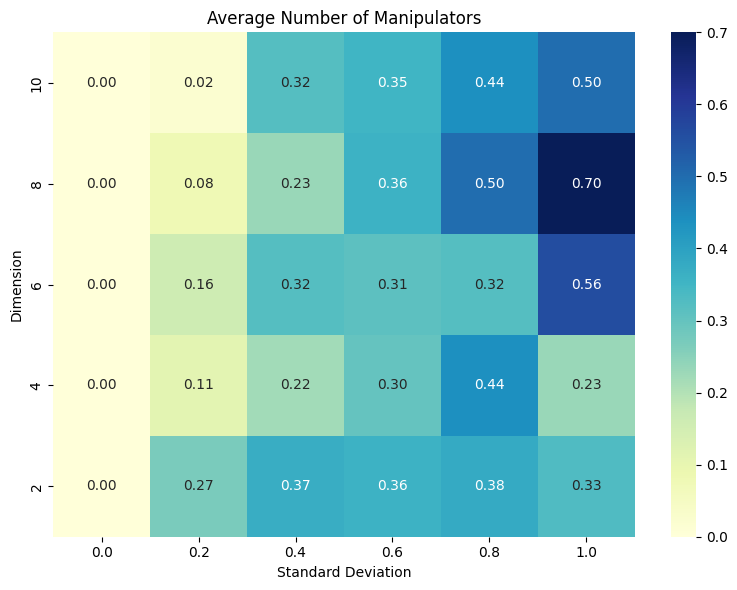

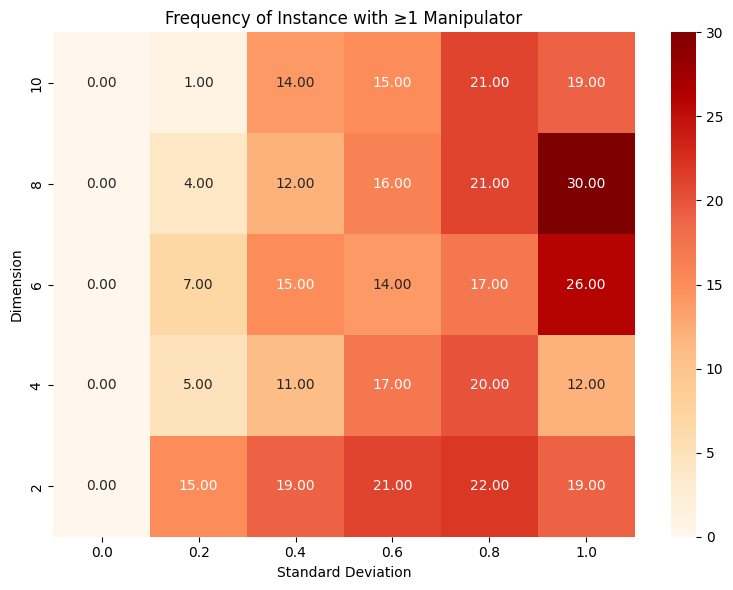

In [74]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("expectations_euclidean_gain.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["max_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.max(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("expectations_euclidean_gain.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["dimension", "std"]).agg(
    max_benefit=("max_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "std", values = "max_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Max Self Benefit")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("expectations_euclidean_gain_max_self_benefit.pdf", format='pdf')
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "std", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("expectations_euclidean_gain_self_avg_num_manipulators.pdf", format='pdf')
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "std", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("expectations_euclidean_gain_self_freq.pdf", format='pdf')
plt.show()


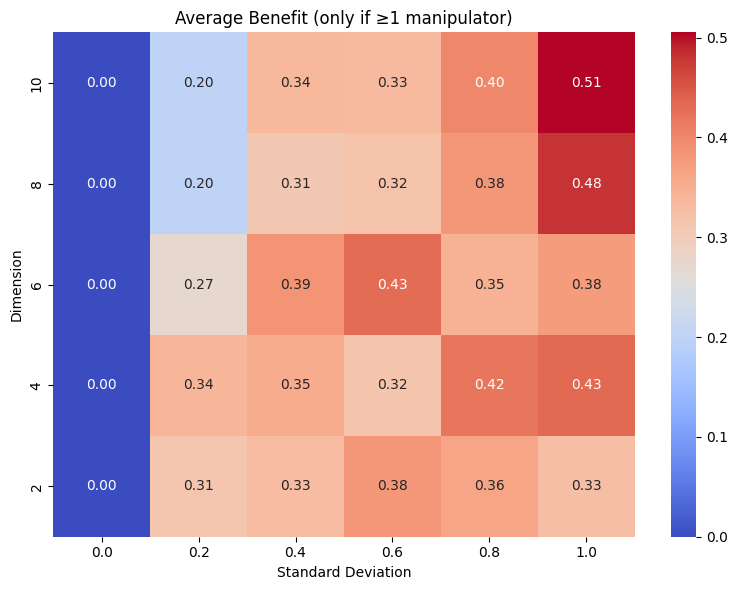

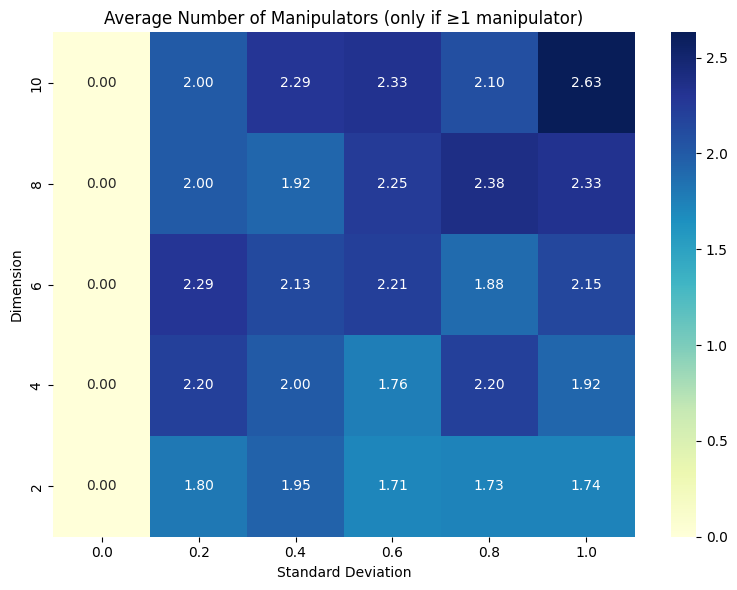

In [52]:
# --- Conditional averages: only over instances with at least one manipulator ---

# Filter rows where there is at least one manipulator
df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["dimension", "std"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["dimension", "std"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["dimension", "std"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["dimension", "std"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["dimension", "std"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["dimension", "std"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = avg_benefit_cond.pivot_table(
    index="dimension", columns="std", values="avg_self_benefit"
)

num_manip_cond_matrix = avg_num_manip_cond.pivot_table(
    index="dimension", columns="std", values="num_self_manipulators"
)

# --- Plotting ---

plt.figure(figsize=(8, 6))
sns.heatmap(benefit_cond_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit (only if ≥1 manipulator)")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig("expectations_euclidean_gain_avg_self_benefit_one.pdf", format='pdf')
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(num_manip_cond_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators (only if ≥1 manipulator)")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig("expectations_euclidean_gain_num_self_manip_one.pdf", format='pdf')
plt.show()


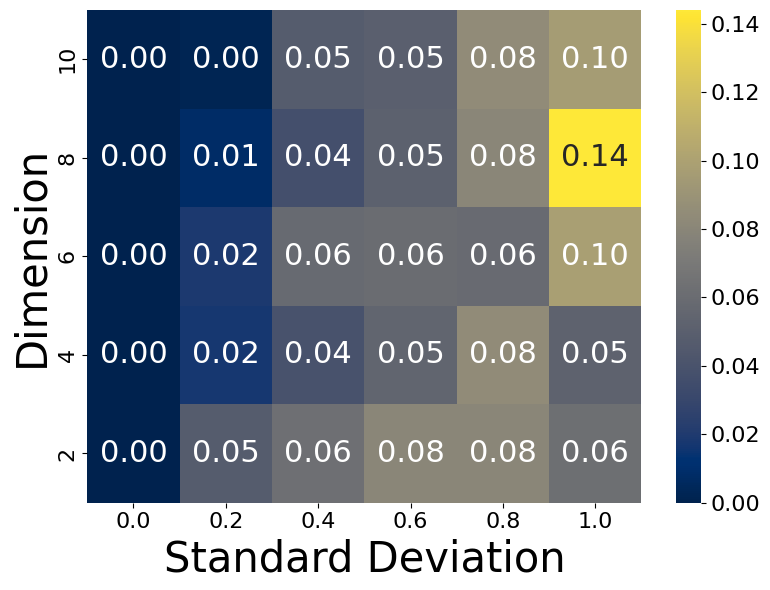

In [24]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("expectations_euclidean_gain.csv")

# Safely convert string to list (if needed)

def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "std"])["avg_self_benefit"].mean().reset_index()

#heatmap_data["avg_self_benefit"] = heatmap_data["avg_self_benefit"] /10


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="std", values="avg_self_benefit")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="cividis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel("Standard Deviation", fontsize = 30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("expectations_euclidean_gain_avg_self_benefit.pdf", format="pdf")
plt.show()


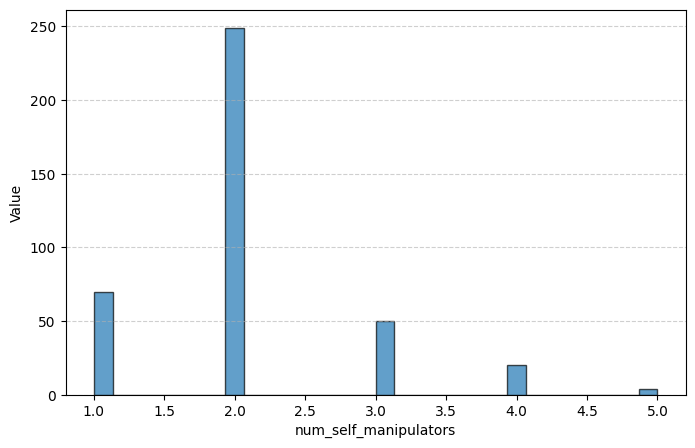

num_self_manipulators mean: 2.0814
num_self_manipulators median: 2.0000
num_self_manipulators max: 5.0000


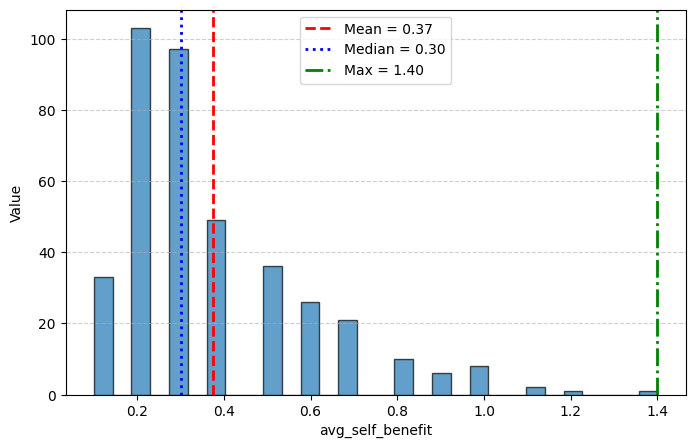

Mean of avg_self_benefit: 0.3743
Median of avg_self_benefit: 0.3000
Max of avg_self_benefit: 1.4000


In [8]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("expectations_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())
df= df[df["num_self_manipulators"] > 0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["num_self_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("num_self_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["num_self_manipulators"].mean()

median_val = df["num_self_manipulators"].median()

max_val = df["num_self_manipulators"].max()
 
print(f"num_self_manipulators mean: {mean_val:.4f}")

print(f"num_self_manipulators median: {median_val:.4f}")

print(f"num_self_manipulators max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("expectations_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["avg_self_benefit"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["avg_self_benefit"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("avg_self_benefit")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["avg_self_benefit"].mean()

median_pos = positive_df["avg_self_benefit"].median()

max_pos = positive_df["avg_self_benefit"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of avg_self_benefit: {mean_pos:.4f}")

print(f"Median of avg_self_benefit: {median_pos:.4f}")

print(f"Max of avg_self_benefit: {max_pos:.4f}")

 

**Fame Euclidean**

In [16]:
data_fame_euclidean_gain = []

n=10
f_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list = [2, 3, 5, 10]

for d in tqdm(d_list):
    number_phi = []
    for f in tqdm(f_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            pref = generate_fame_votes(n, d, 'uniform', f)
            mpref=pref[0]
            wpref=pref[1]
            preferences = [mpref, wpref]
            benefit_women = []
            manipulated_matchings = []
            original_matchings = []
            manipulated_preferences = []
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                matching2 = result[0]
                rk1 = 1000
                rk2 = 1000
                for i in range(0,n):
                    if matching[i] == manipulator:
                        partner1=i+1
                    if matching2[i] == manipulator:
                        partner2=i+1
                w_pref = wpref[manipulator-1]
                for i in range(0,n):
                    if w_pref[i] == partner1:
                        rk1=i
                    if w_pref[i] == partner2:
                        rk2=i
                manipulated_matchings.append(matching2)
                original_matchings.append(matching)
                manipulated_preferences.append(result[1])
                #print(rk1, rk2)
                benefit = abs(rk1-rk2)
                benefit_women.append(benefit)
            data_fame_euclidean_gain.append([d, f, preferences, samples, manipulated_preferences, original_matchings, manipulated_matchings, benefit_women])

                #save phim, phiw, sample, manipulator, manipulated_preference (that would be result[1]), matching, matching2, benefit 
            #print(benefit_women)
            #benefit_avg = sum(benefit_women)/len(benefit_women)
            #print(benefit_avg)




100%|██████████| 4/4 [00:02<00:00,  1.41it/s]


In [17]:
df7 = pd.DataFrame(data_fame_euclidean_gain, columns=["dimension", "fame", "preferences", "sample", "manipulated preference", "original matching", "manipulated matching", "benefit"])
df7.to_csv('fame_euclidean_gain.csv', index=False)

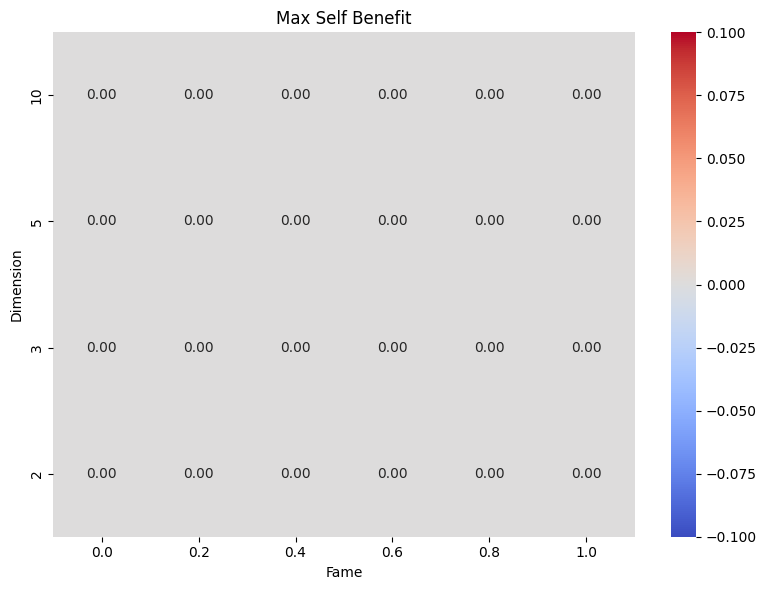

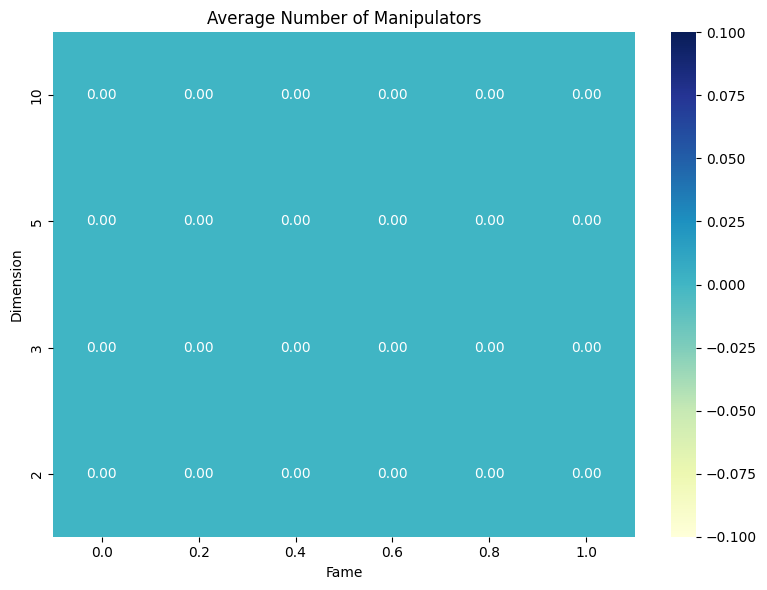

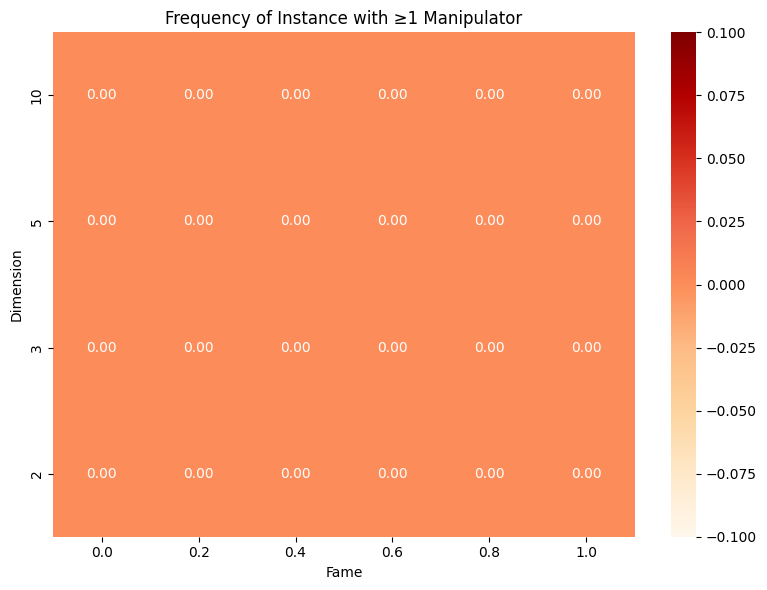

In [75]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("fame_euclidean_gain.csv")

# --- Parse "benefit" column into actual Python lists ---
df["self_benefit_parsed"] = df["benefit"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# --- Compute required new columns ---
# (a) average benefit = sum(list)/10
df["max_self_benefit"] = df["self_benefit_parsed"].apply(
    lambda lst: np.max(lst) if lst else 0
)

# (b) number of manipulators = number of entries > 0
df["num_self_manipulators"] = df["self_benefit_parsed"].apply(
    lambda lst: np.sum(np.array(lst) > 0) if lst else 0
)

# (c) frequency of instance = 1 if any manipulator exists
df["self_freq_instance"] = df["num_self_manipulators"].apply(
    lambda x: 1 if x > 0 else 0
)

# --- Save updated file ---
df.to_csv("fame_euclidean_gain.csv", index=False)

# --- Group by phi_m, phi_w and average across 100 samples ---
grouped = df.groupby(["dimension", "fame"]).agg(
    max_benefit=("max_self_benefit", "mean"),
    avg_num_manipulators=("num_self_manipulators", "mean"),
    freq_instance=("self_freq_instance", "sum")
).reset_index()

# --- Heatmap 1: Average Self Benefit ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "fame", values = "max_benefit")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Max Self Benefit")
plt.xlabel("Fame")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 2: Average Number of Manipulators ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "fame", values = "avg_num_manipulators")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators")
plt.xlabel("Fame")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# --- Heatmap 3: Frequency of Instances with ≥1 Manipulator ---
plt.figure(figsize=(8,6))
heatmap_matrix = grouped.pivot(index = "dimension", columns = "fame", values = "freq_instance")
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="OrRd")
plt.title("Frequency of Instance with ≥1 Manipulator")
plt.xlabel("Fame")
plt.ylabel("Dimension")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


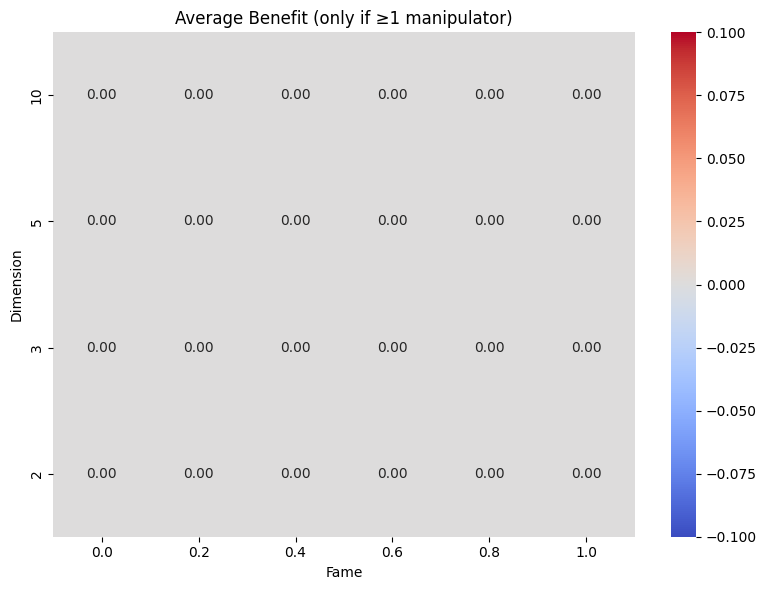

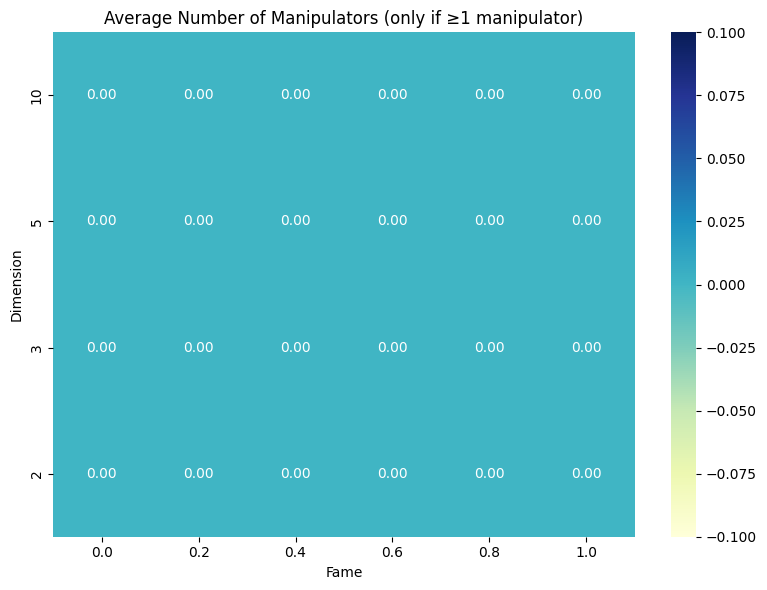

In [37]:
# --- Conditional averages: only over instances with at least one manipulator ---

# Filter rows where there is at least one manipulator
df_with_manip = df[df["num_self_manipulators"] > 0]

# (1) Average benefit when there is at least one manipulator
avg_benefit_cond = (
    df_with_manip.groupby(["dimension", "fame"])["avg_self_benefit"]
    .mean()
    .reset_index()
)

# (2) Average number of manipulators when there is at least one manipulator
avg_num_manip_cond = (
    df_with_manip.groupby(["dimension", "fame"])["num_self_manipulators"]
    .mean()
    .reset_index()
)

# --- Build full grid of phi_m, phi_w combinations ---
all_combos = (
    df.groupby(["dimension", "fame"])
    .size()
    .reset_index()
    .rename(columns={0: "count"})
)[["dimension", "fame"]]

# Merge conditional results with full grid
avg_benefit_cond = all_combos.merge(avg_benefit_cond, on=["dimension", "fame"], how="left")
avg_num_manip_cond = all_combos.merge(avg_num_manip_cond, on=["dimension", "fame"], how="left")

# Fill missing entries (those with no manipulators at all) with 0
avg_benefit_cond["avg_self_benefit"] = avg_benefit_cond["avg_self_benefit"].fillna(0)
avg_num_manip_cond["num_self_manipulators"] = avg_num_manip_cond["num_self_manipulators"].fillna(0)

# Now pivot into matrices
benefit_cond_matrix = avg_benefit_cond.pivot_table(
    index="dimension", columns="fame", values="avg_self_benefit"
)

num_manip_cond_matrix = avg_num_manip_cond.pivot_table(
    index="dimension", columns="fame", values="num_self_manipulators"
)

# --- Plotting ---

plt.figure(figsize=(8, 6))
sns.heatmap(benefit_cond_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit (only if ≥1 manipulator)")
plt.xlabel("Fame")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(num_manip_cond_matrix, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average Number of Manipulators (only if ≥1 manipulator)")
plt.xlabel("Fame")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()
